[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jadg1/economic-networks-seminar/blob/main/labs/school_gossip.ipynb)

**Run it in Google Colab, with nothing to install:** click the badge, then run the setup cell below first. On your own computer the setup cell does nothing.

In [ ]:
# Setup for Google Colab: gets the repository's files and the two extra packages.
# On your own computer (with the econ-networks environment) this cell does nothing.
import os, sys
if "google.colab" in sys.modules:
    REPO = "jadg1/economic-networks-seminar"
    if not os.path.exists("/content/economic-networks-seminar"):
        !git clone -q --depth 1 https://github.com/{REPO}.git /content/economic-networks-seminar
    %cd /content/economic-networks-seminar/labs
    %pip install -q pyreadr pyvis
    print("Ready: running from the repository's labs folder.")

# School gossip: who is the best person to tell a rumour?

Economic Networks, Part 3  

Data: an excerpt of the Teenage Friends and Lifestyle Study (Glasgow), the  
friendships of 50 girls in one secondary school, aged about 13 at the first  
survey in February 1995, measured three times over two school years, plus their  
smoking. Distributed with the RSiena package for teaching  
(https://www.stats.ox.ac.uk/~snijders/siena/s50_data.htm).  

The demo:  
1. build the friendship network,  
2. start a rumour from each girl in turn and see how far it travels,  
3. ask which network measure predicts the best gossip,  
4. (bonus) do smokers have smoking friends?  

The rumour model is Maki-Thompson: each spreader tells one random friend per  
step; telling someone who already knows makes the spreader lose interest.  

`Needs: pip install networkx matplotlib numpy scipy pyreadr requests`

> The first run downloads the Glasgow data (`RSiena.rda`) from GitHub, so it needs internet once.

## Setup and data

In [1]:
%matplotlib inline

In [2]:
import os
import random
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

DATA_URL = "https://github.com/stocnet/rsiena/raw/main/data/RSiena.rda"
DATA_FILE = "RSiena.rda"
BLUE, CORAL, INK, MUTED, LINE = "#2D6CF6", "#F2464F", "#1B1F3B", "#8A8FA8", "#C9CCD8"


def load_school(wave=1):
    """Friendship network (undirected: a link if either girl named the other)
    and smoking (True = occasional or regular smoker) at a given wave."""
    import pyreadr
    if not os.path.exists(DATA_FILE):
        import requests
        resp = requests.get(DATA_URL, timeout=60)
        resp.raise_for_status()                    # don't save an error page as the data
        with open(DATA_FILE, "wb") as f:
            f.write(resp.content)
    r = pyreadr.read_r(DATA_FILE)
    A = r[f"s50{wave}"].values
    smoke = r["s50s"].values[:, wave - 1] > 1
    G = nx.from_numpy_array((A > 0).astype(int), create_using=nx.DiGraph).to_undirected()
    G = nx.relabel_nodes(G, {i: i + 1 for i in G})          # girls numbered 1 to 50
    return G, {i + 1: bool(s) for i, s in enumerate(smoke)}

## The rumour model

In [3]:
def spread_rumour(G, start, rng):
    """One rumour (Maki-Thompson). Returns the share of girls who heard it."""
    state = {v: "ignorant" for v in G}
    state[start] = "spreader"
    heard = 1
    while any(s == "spreader" for s in state.values()):
        for v in [v for v, s in state.items() if s == "spreader"]:
            friends = list(G[v])
            if not friends:
                state[v] = "stifler"
                continue
            u = rng.choice(friends)
            if state[u] == "ignorant":
                state[u] = "spreader"
                heard += 1
            else:
                state[v] = "stifler"              # old news: lose interest
    return heard / len(G)


def average_reach(G, runs=300, seed=1):
    rng = random.Random(seed)
    return {v: np.mean([spread_rumour(G, v, rng) for _ in range(runs)]) for v in G}

## Run everything

In [4]:
G, smokes = load_school(wave=1)
groups = sorted(nx.connected_components(G), key=len, reverse=True)
print(f"{G.number_of_nodes()} girls, {G.number_of_edges()} friendships")
print(f"Largest friendship group: {len(groups[0])} girls; "
      f"{nx.number_of_isolates(G)} girls with no friends named in the excerpt")

reach = average_reach(G)
best = sorted(reach, key=reach.get, reverse=True)[:3]
print("\nBest people to tell a rumour (average share of the school who hear it):")
for v in best:
    print(f"  girl {v:2d}: {reach[v]:.0%}   ({G.degree(v)} friends)")
print(f"Average over all girls: {np.mean(list(reach.values())):.0%}")
print(f"If everyone told ALL their friends, the best start would reach "
      f"{len(groups[0]) / len(G):.0%} (her whole friendship group)")

print("\nWhich measure predicts the best gossip? (rank correlation with reach)")
linked = [v for v in G if G.degree(v) > 0]
measures = {"Degree": nx.degree_centrality(G),
            "Betweenness": nx.betweenness_centrality(G),
            "Eigenvector": nx.eigenvector_centrality(G, max_iter=2000),
            "Closeness": nx.closeness_centrality(G)}
corr = {}
for name, m in measures.items():
    corr[name] = spearmanr([m[v] for v in linked], [reach[v] for v in linked]).correlation
    print(f"  {name:12s} {corr[name]:.2f}")

G3, _ = load_school(wave=3)
reach3 = average_reach(G3)
print(f"\nTwo school years later (wave 3) the best gossip is girl "
      f"{max(reach3, key=reach3.get)} (wave 1: girl {best[0]})")

smoker_friends = lambda group: np.mean([np.mean([smokes[u] for u in G[v]])
                                        for v in group if G.degree(v)])
print(f"\nBonus: friends who smoke, wave 1. Smokers: {smoker_friends([v for v in G if smokes[v]]):.0%}. "
      f"Non-smokers: {smoker_friends([v for v in G if not smokes[v]]):.0%}.")

50 girls, 74 friendships
Largest friendship group: 33 girls; 3 girls with no friends named in the excerpt



Best people to tell a rumour (average share of the school who hear it):
  girl 19: 21%   (6 friends)
  girl 26: 20%   (5 friends)
  girl 11: 19%   (8 friends)
Average over all girls: 13%
If everyone told ALL their friends, the best start would reach 66% (her whole friendship group)

Which measure predicts the best gossip? (rank correlation with reach)
  Degree       0.62
  Betweenness  0.75
  Eigenvector  0.85
  Closeness    0.96



Two school years later (wave 3) the best gossip is girl 15 (wave 1: girl 19)

Bonus: friends who smoke, wave 1. Smokers: 45%. Non-smokers: 15%.


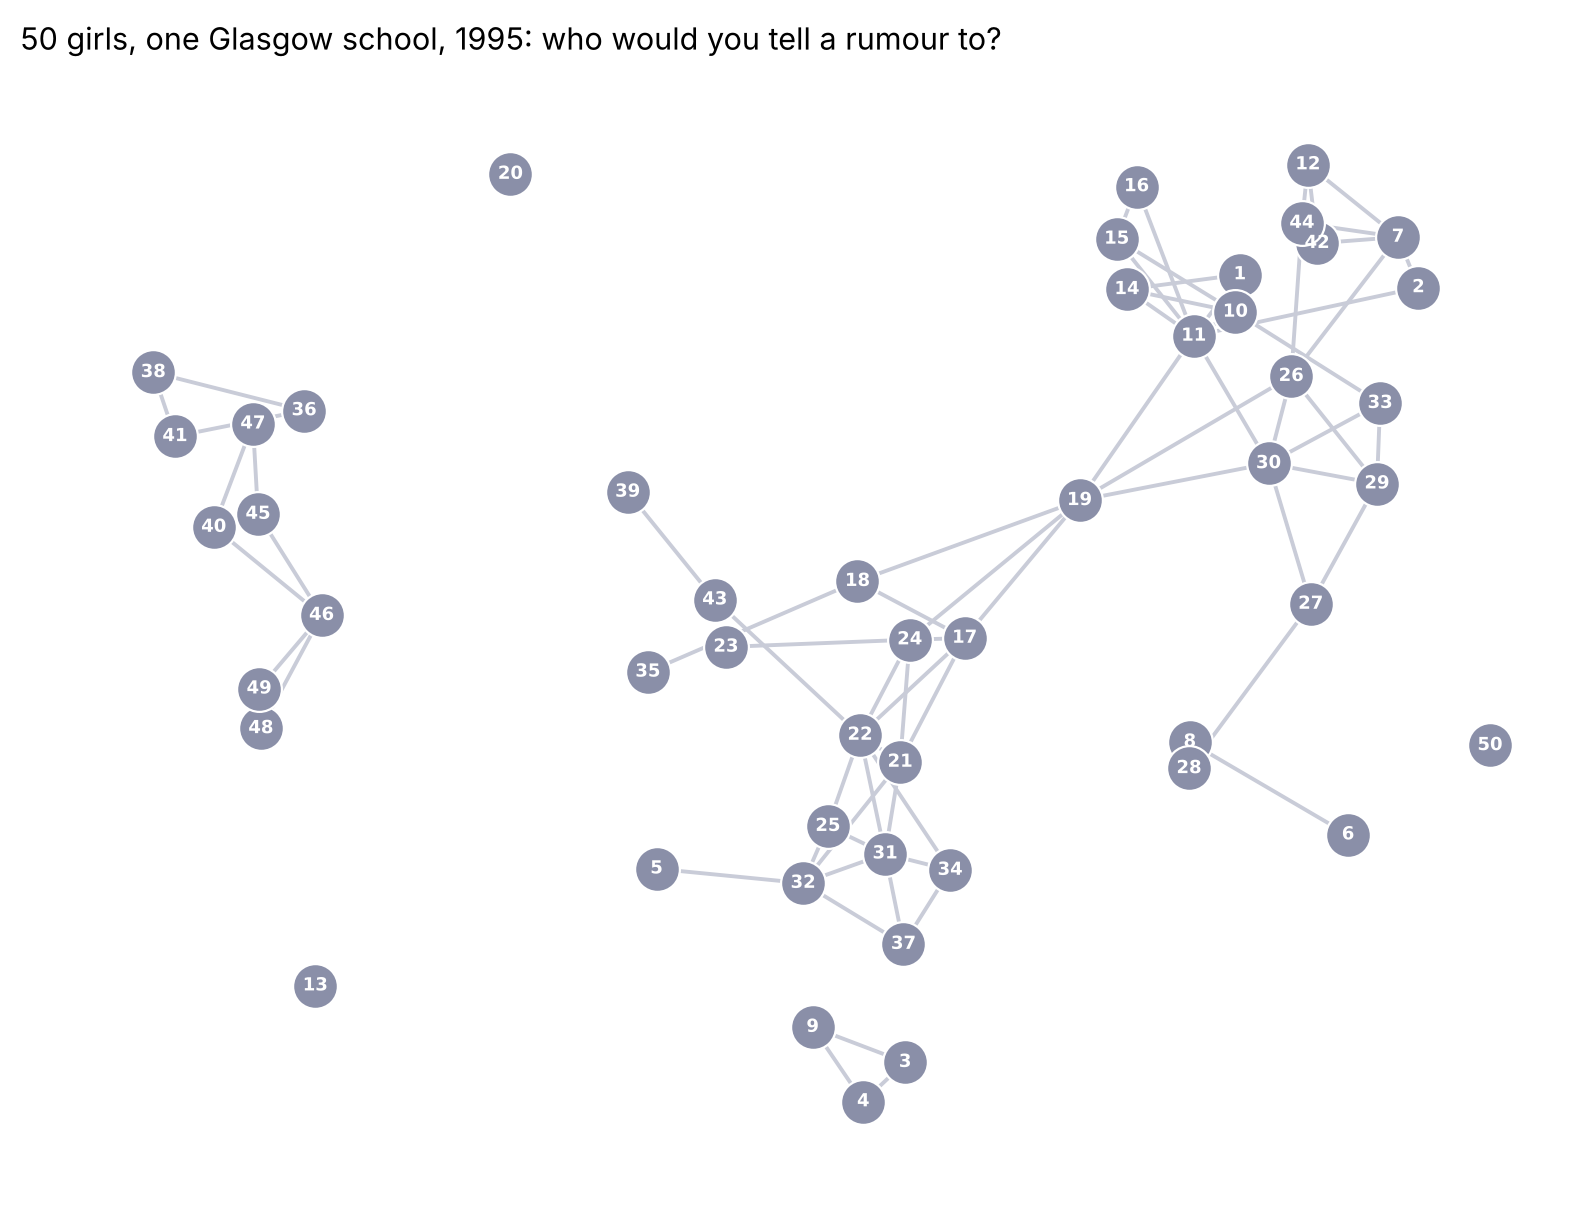

In [5]:
# Figure 0: the school, plain, for the vote ("who would you tell?")
pos = nx.spring_layout(G, seed=4, k=0.35)
fig, ax = plt.subplots(figsize=(8, 6.2))
nx.draw_networkx_edges(G, pos, ax=ax, edge_color=LINE, width=1.4)
nx.draw_networkx_nodes(G, pos, ax=ax, node_color=MUTED, node_size=260,
                       edgecolors="white", linewidths=0.8)
nx.draw_networkx_labels(G, pos, {v: str(v) for v in G}, ax=ax, font_size=6.5,
                        font_color="white", font_weight="bold")
ax.set_title("50 girls, one Glasgow school, 1995: who would you tell a rumour to?",
             loc="left", fontsize=11)
ax.axis("off")
fig.tight_layout()
fig.savefig("gossip_fig0_vote.png", dpi=160)

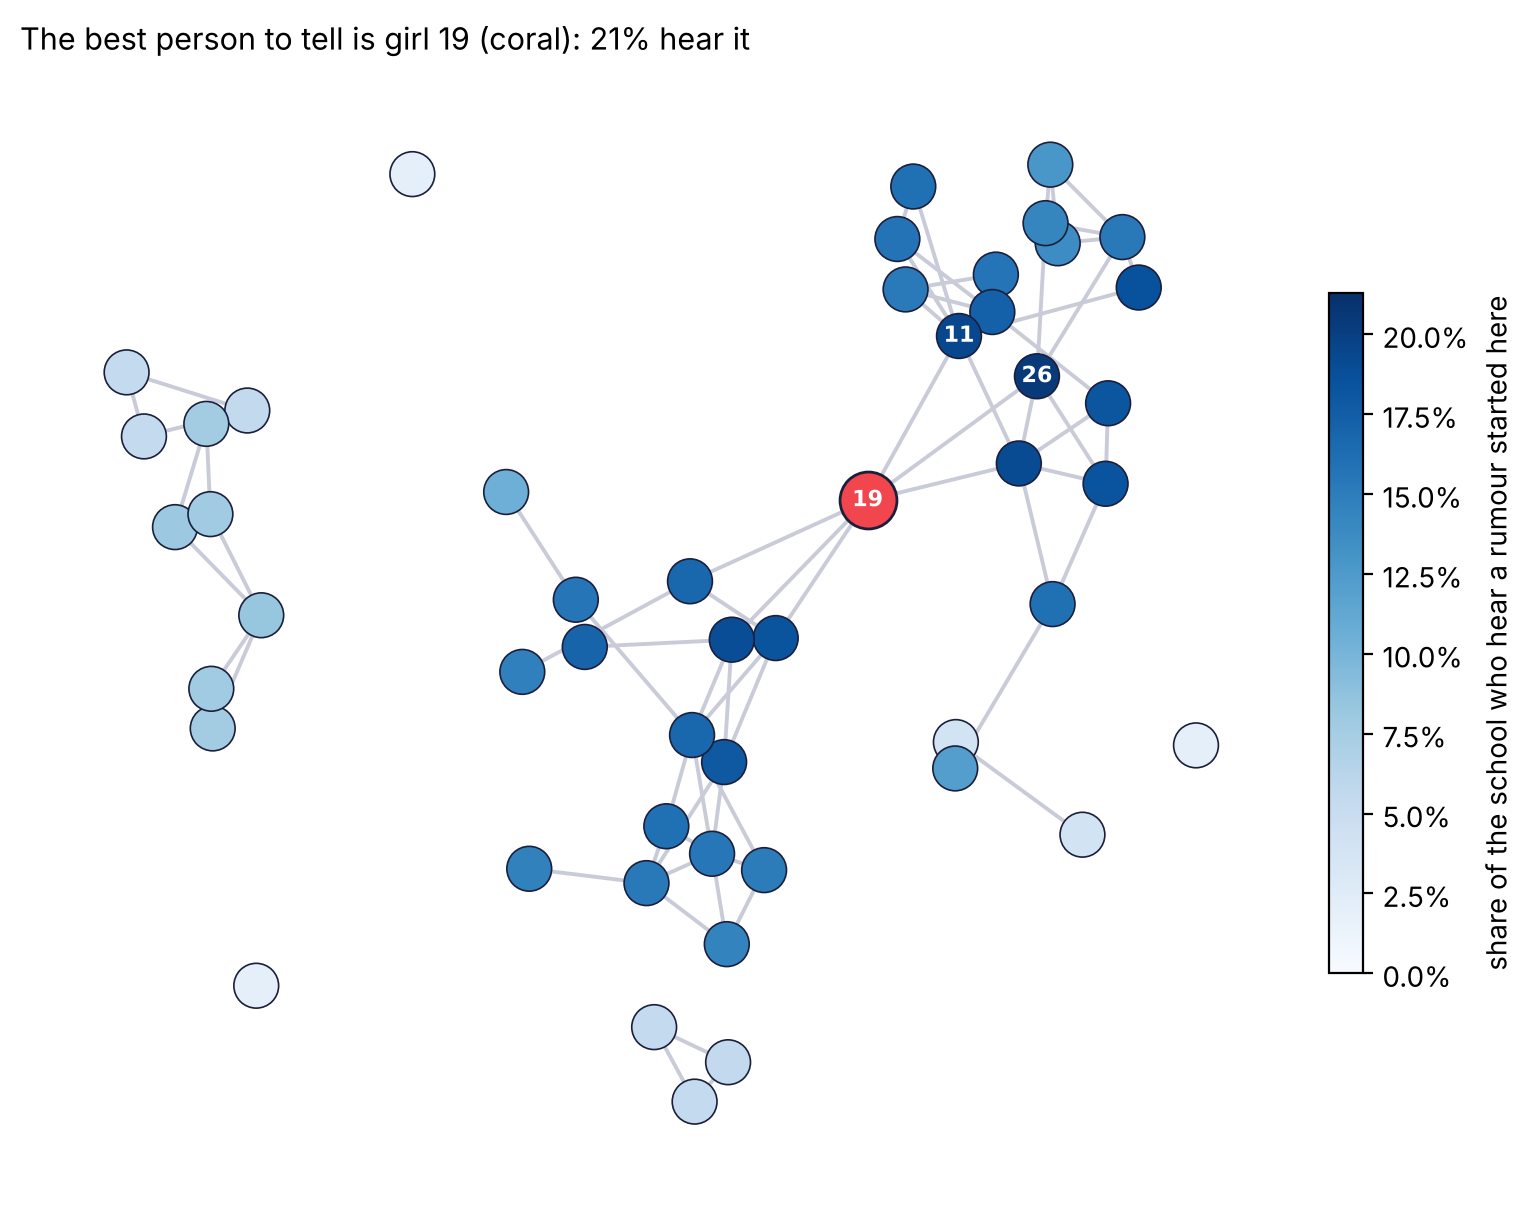

In [6]:
# Figure 1: the school, coloured by how far a rumour started there travels
from matplotlib.ticker import PercentFormatter
fig, ax = plt.subplots(figsize=(8, 6.2))
nx.draw_networkx_edges(G, pos, ax=ax, edge_color=LINE, width=1.4)
nodes = nx.draw_networkx_nodes(G, pos, ax=ax, node_color=[reach[v] for v in G],
                               cmap="Blues", vmin=0, node_size=260,
                               edgecolors=INK, linewidths=0.6)
nx.draw_networkx_nodes(G, pos, nodelist=best[:1], ax=ax, node_color=CORAL,
                       node_size=420, edgecolors=INK, linewidths=1)
nx.draw_networkx_labels(G, pos, {v: str(v) for v in best}, ax=ax,
                        font_size=8, font_weight="bold", font_color="white")
fig.colorbar(nodes, ax=ax, shrink=0.6, format=PercentFormatter(1.0),
             label="share of the school who hear a rumour started here")
ax.set_title(f"The best person to tell is girl {best[0]} (coral): {reach[best[0]]:.0%} hear it",
             loc="left", fontsize=11)
ax.axis("off")
fig.tight_layout()
fig.savefig("gossip_fig1_school.png", dpi=160)


Saved gossip_fig0_vote.png, gossip_fig1_school.png and gossip_fig2_measures.png


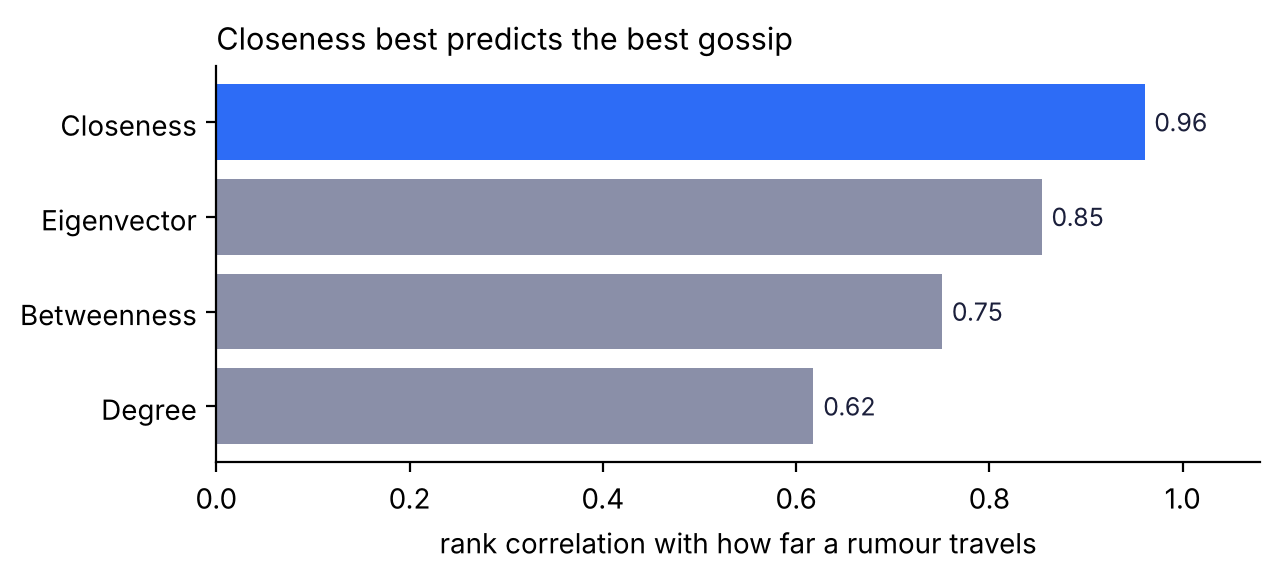

In [7]:
# Figure 2: which measure predicts the best gossip
fig, ax = plt.subplots(figsize=(6.5, 3))
names = sorted(corr, key=corr.get)
ax.barh(names, [corr[n] for n in names],
        color=[BLUE if n == names[-1] else MUTED for n in names])
for i, n in enumerate(names):
    ax.text(corr[n] + 0.01, i, f"{corr[n]:.2f}", va="center", fontsize=9, color=INK)
ax.set_xlim(0, 1.08)
ax.set_xlabel("rank correlation with how far a rumour travels")
ax.set_title("Closeness best predicts the best gossip", loc="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("gossip_fig2_measures.png", dpi=160)
print("\nSaved gossip_fig0_vote.png, gossip_fig1_school.png and gossip_fig2_measures.png")